In [48]:
import numpy as np
import matplotlib.pyplot as plt
import os
import json
import math
from matplotlib.pyplot import cm

plt.style.use('seaborn-v0_8') # I personally prefer seaborn for the graph style, but you may choose whichever you want.
params = {"ytick.color" : "black",
          "xtick.color" : "black",
          "axes.labelcolor" : "black",
          "axes.edgecolor" : "black",
          "text.usetex" : True,
          "font.family" : "serif",
          "font.serif" : ["Computer Modern Serif"]}
plt.rcParams.update(params)

output_dir = "/Users/russell/projects/stencil_research/cpu_attention_suite/plots"

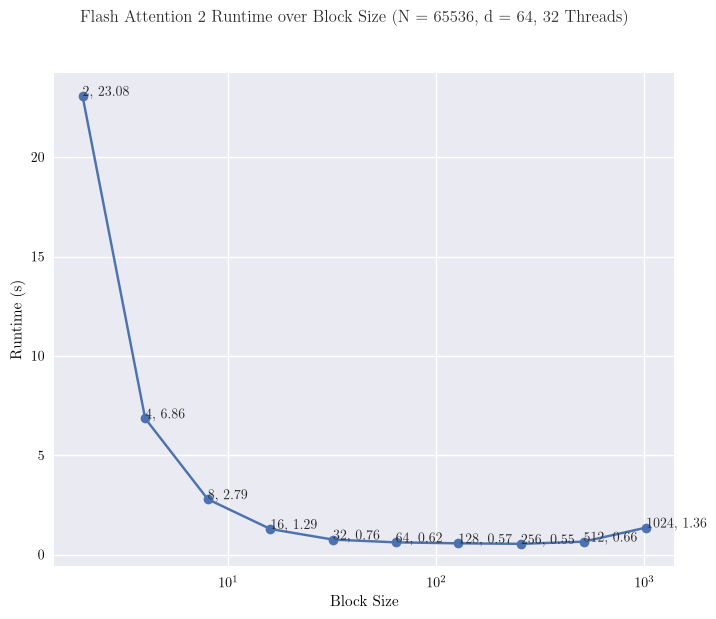

In [49]:
results_dirs = [
    "/Users/russell/projects/stencil_research/cpu_attention_suite/results/fa2_blocksize_sweep",
]

plot_data = {}

def load_results_file(path):
    with open(json_path, 'r') as json_file:
        data = json.load(json_file)
        block_size = data["block_size"]
        time = np.average(data["times"]) / 1000.0
        plot_data[block_size] = time;
        
for results_dir in results_dirs:  
    for file in sorted(os.listdir(results_dir)):
        json_path = f"{results_dir}/{file}"
        load_results_file(json_path)

block_sizes = sorted(plot_data.keys())
times = [plot_data[block_size] for block_size in block_sizes]

width = 8
height_ratio = 0.8
fig = plt.figure(figsize=(width, width * height_ratio))
n_rows = 1
n_cols = 1
width_ratios = [1.0]
height_ratios = [1.0]
gs1 = fig.add_gridspec(
    n_rows, n_cols,
    width_ratios = width_ratios, 
    height_ratios = height_ratios,
    wspace = 0.45,
    hspace = 0.45,
)
ax_1 = fig.add_subplot(gs1[0, 0])


ax_1.plot(
    block_sizes, 
    times,
    marker='o',
)
for i,j in zip(block_sizes,times):
    ax_1.annotate(f"{i}, {j:.2f}",xy=(i,j))
    
ax_1.set_xticks(block_sizes)
ax_1.set_ylabel("Runtime (s)")
ax_1.set_xlabel("Block Size")
#ax_1.legend()
ax_1.set_xscale('log')
#ax_1.set_yscale('log')


fig.suptitle("Flash Attention 2 Runtime over Block Size (N = 65536, d = 64, 32 Threads)")
plt.savefig(f"{output_dir}/fas2_blocksize_sweep.pdf")

In [50]:
times

[np.float64(23.082888733999997),
 np.float64(6.8575148048),
 np.float64(2.7913882628),
 np.float64(1.2926889702000002),
 np.float64(0.7591066063999999),
 np.float64(0.6216866487999999),
 np.float64(0.5715851844000001),
 np.float64(0.5461690018),
 np.float64(0.655346929),
 np.float64(1.3636714948000002)]

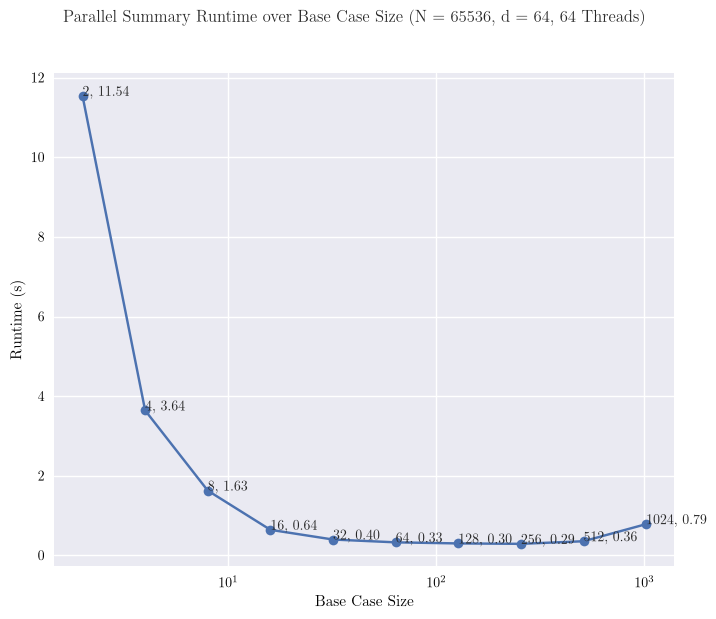

In [51]:
results_dirs = [
    "/Users/russell/projects/stencil_research/cpu_attention_suite/results/rec_basesize_sweep",
]

plot_data = {}

def load_results_file(path):
    with open(json_path, 'r') as json_file:
        data = json.load(json_file)
        block_size = data["base_size"]
        time = np.average(data["times"]) / 1000.0
        plot_data[block_size] = time;
        
for results_dir in results_dirs:  
    for file in sorted(os.listdir(results_dir)):
        json_path = f"{results_dir}/{file}"
        load_results_file(json_path)

block_sizes = sorted(plot_data.keys())
times = [plot_data[block_size] for block_size in block_sizes]

width = 8
height_ratio = 0.8
fig = plt.figure(figsize=(width, width * height_ratio))
n_rows = 1
n_cols = 1
width_ratios = [1.0]
height_ratios = [1.0]
gs1 = fig.add_gridspec(
    n_rows, n_cols,
    width_ratios = width_ratios, 
    height_ratios = height_ratios,
    wspace = 0.45,
    hspace = 0.45,
)
ax_1 = fig.add_subplot(gs1[0, 0])


ax_1.plot(
    block_sizes, 
    times,
    marker="o",
)
for i,j in zip(block_sizes,times):
    ax_1.annotate(f"{i}, {j:.2f}",xy=(i,j))
    
ax_1.set_xticks(block_sizes)
ax_1.set_ylabel("Runtime (s)")
ax_1.set_xlabel("Base Case Size")
#ax_1.legend()
ax_1.set_xscale('log')
#ax_1.set_yscale('log')


fig.suptitle("Parallel Summary Runtime over Base Case Size (N = 65536, d = 64, 64 Threads)")
plt.savefig(f"{output_dir}/rec_basecase_sweep.pdf")

In [52]:
times

[np.float64(11.542659096),
 np.float64(3.6410396236),
 np.float64(1.6275245378),
 np.float64(0.6424547182),
 np.float64(0.3986048452),
 np.float64(0.32797303359999996),
 np.float64(0.3005442864),
 np.float64(0.290286249),
 np.float64(0.355530204),
 np.float64(0.7853781508)]